# 📊 Federal Reserve SEP — Multimodal RAG 실행 결과 검증

**개인 과제 | 수업 실습 01·02·03을 Python 파일 3개로 통합**

- PDF: [Federal Reserve, Summary of Economic Projections (2024.12.18)](https://www.federalreserve.gov/monetarypolicy/files/fomcprojtabl20241218.pdf) · 17페이지
- 프로그램: `src/extract.py` → `src/summarize.py` → `src/retriever.py`
- 검증 대상: PDF 추출·분할, 텍스트/표/이미지 요약, 5개 답변, Before/After 비교

> **실행 안내:** 이 노트북은 이미 실행된 Python 스크립트가 저장한 파일을 확인하는 용도입니다. `RUN_SCRIPTS = False`는 유지하세요. API 키를 다시 사용하거나 파일을 재생성하지 않습니다. 출력은 본인의 로컬 `.venv`에서 전체 실행 후 저장해야 합니다.

## 0. 환경 및 프로젝트 경로

필요한 로컬 파일:

- `data/fed_sep_2024_12.pdf` — 직접 내려받은 PDF (GitHub 업로드 제외)
- `data/processed/extracted.pkl` — `extract.py` 실행 결과
- `data/processed/summaries.pkl` — `summarize.py` 실행 결과
- `data/figures/*.png` — 이번 PDF의 표·그래프 페이지
- `results/qa_results.json`, `qa_results.md`, `before_after.txt`, `before_after.png` — `retriever.py` 실행 결과

**파일은 본인이 만든 신뢰할 수 있는 pickle만 불러옵니다.**

In [1]:
import sys
import json
import pickle
import subprocess
from pathlib import Path
from IPython.display import display, Markdown, Image

# 이 노트북을 프로젝트 루트 또는 notebooks/ 아래에서 실행할 수 있도록 경로 탐색
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates
     if (p / "src" / "extract.py").is_file()
     and (p / "src" / "summarize.py").is_file()
     and (p / "src" / "retriever.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "프로젝트 루트를 찾지 못했습니다. notebooks/ 폴더를 저장소 안에 두고 다시 실행하세요."
    )

RUN_SCRIPTS = False  # 이번 과제는 이미 실행했으므로 False 유지: API 재호출하지 않음
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = DATA_DIR / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"

print("Python:", sys.version.split()[0])
print("Python 실행 경로:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 존재:", (DATA_DIR / "fed_sep_2024_12.pdf").is_file())
print("재실행 여부:", RUN_SCRIPTS)


Python: 3.11.9
Python 실행 경로: c:\soeundipiateez\multimodal-rag\.venv\Scripts\python.exe
프로젝트 루트: c:\soeundipiateez\multimodal-rag
PDF 존재: True
재실행 여부: False


## 1. 데이터 추출 — 실습 01 (`extract.py`)

사용 함수: `partition_pdf(strategy="hi_res")`, `extract_pdf_elements()`, `categorize_elements()`, `CharacterTextSplitter.from_tiktoken_encoder()`.

- 이번 실행 로그: **17페이지 · 전체 요소 16개 · 텍스트 13개 · 표 3개 · 청크 5개**
- PDF의 벡터 그래프를 보존하기 위해 **표/그래프 페이지 PNG 6개**를 별도로 생성했습니다.

아래 셀은 로그의 숫자를 복사하지 않고 실제 `extracted.pkl`을 읽어 검증합니다.

In [2]:
def run_stage(script_name: str, expected_file: Path):
    """필요할 때만 기존 src/*.py를 실행하고, 기본적으로는 저장된 결과를 재사용."""
    if RUN_SCRIPTS:
        print(f"[실행 시작] src/{script_name}")
        completed = subprocess.run(
            [sys.executable, str(PROJECT_ROOT / "src" / script_name)],
            cwd=str(PROJECT_ROOT),
            capture_output=True,
            text=True,
            errors="replace",
        )
        print(completed.stdout[-12000:])
        if completed.returncode != 0:
            print(completed.stderr[-8000:])
            raise RuntimeError(f"{script_name} 실행 실패 (exit {completed.returncode})")
    else:
        print(f"[저장 결과 사용] {expected_file.relative_to(PROJECT_ROOT)}")

    if not expected_file.is_file():
        raise FileNotFoundError(
            f"결과 파일이 없습니다: {expected_file}\n"
            f"프로젝트 루트의 터미널에서 python src/{script_name} 를 먼저 실행하세요."
        )

run_stage("extract.py", PROCESSED_DIR / "extracted.pkl")


[저장 결과 사용] data\processed\extracted.pkl


In [3]:
# pickle은 본인이 직접 생성한 신뢰 가능한 파일만 읽으세요.
with (PROCESSED_DIR / "extracted.pkl").open("rb") as file:
    extracted = pickle.load(file)

texts = extracted["texts"]
tables = extracted["tables"]
chunks = extracted["texts_2k_token"]
figure_names = extracted.get("figure_names", [])

print("원본 텍스트 블록:", len(texts))
print("원본 표 블록:", len(tables))
print("텍스트 청크:", len(chunks))
print("이번 PDF PNG 저장 대상:", len(figure_names))
print("PNG 목록:", figure_names)
print("대상 PNG 실제 존재:", sum((FIGURES_DIR / name).is_file() for name in figure_names), "/", len(figure_names))

assert len(texts) > 0, "텍스트 추출이 비어 있습니다."
assert len(tables) > 0, "평가 기준상 Table 객체가 추출되었는지 확인이 필요합니다."
assert len(chunks) > 0, "청크 추출이 비어 있습니다."
print("\n[텍스트 청크 1 예시]\n", chunks[0][:480])
print("\n[표 원본 1 예시]\n", tables[0][:480])

assert len(figure_names) == 6, "선정한 PNG 6개인지 확인하세요."
assert all((FIGURES_DIR / name).is_file() for name in figure_names), "일부 PNG 이미지가 없습니다."

원본 텍스트 블록: 13
원본 표 블록: 3
텍스트 청크: 5
이번 PDF PNG 저장 대상: 6
PNG 목록: ['table1_economic_projections_p2.png', 'figure1_projection_ranges_p3.png', 'figure2_dot_plot_p4.png', 'figure3_gdp_distribution_p5.png', 'figure4a_gdp_uncertainty_p10.png', 'table2_historical_errors_p16.png']
대상 PNG 실제 존재: 6 / 6

[텍스트 청크 1 예시]
 For release at 2:00 p.m., EST, December 18, 2024

Summary of Economic Projections

In conjunction with the Federal Open Market Committee (FOMC) meeting held on December 17–18, 2024, meeting participants submitted their projections of the most likely outcomes for real gross domestic product (GDP) growth, the unemployment rate, and inﬂation for each year from 2024 to 2027 and over the longer run. Each participant’s projections were based on information available at the time of 

[표 원본 1 예시]
 Median1 Central Tendency2 Range3 Variable 2024 2025 2026 2027 Longer 2024 2025 2026 2027 Longer 2024 2025 2026 run run Change in real GDP 2.5 2.1 2.0 1.9 1.8 2.4–2.5 1.8–2.2 1.9–2.1 1.8–2.0 1.7–2.0

### 원본 표와 그래프 시각 검증

`data/figures`의 이번 PDF 페이지를 표시합니다. 다음 셀 출력은 `.ipynb`에 이미지로 남으므로 제출 증빙으로 활용할 수 있습니다. 그래프와 표를 직접 눈으로 확인하세요.


 Table 1 — 경제전망 표 (PDF p.2)


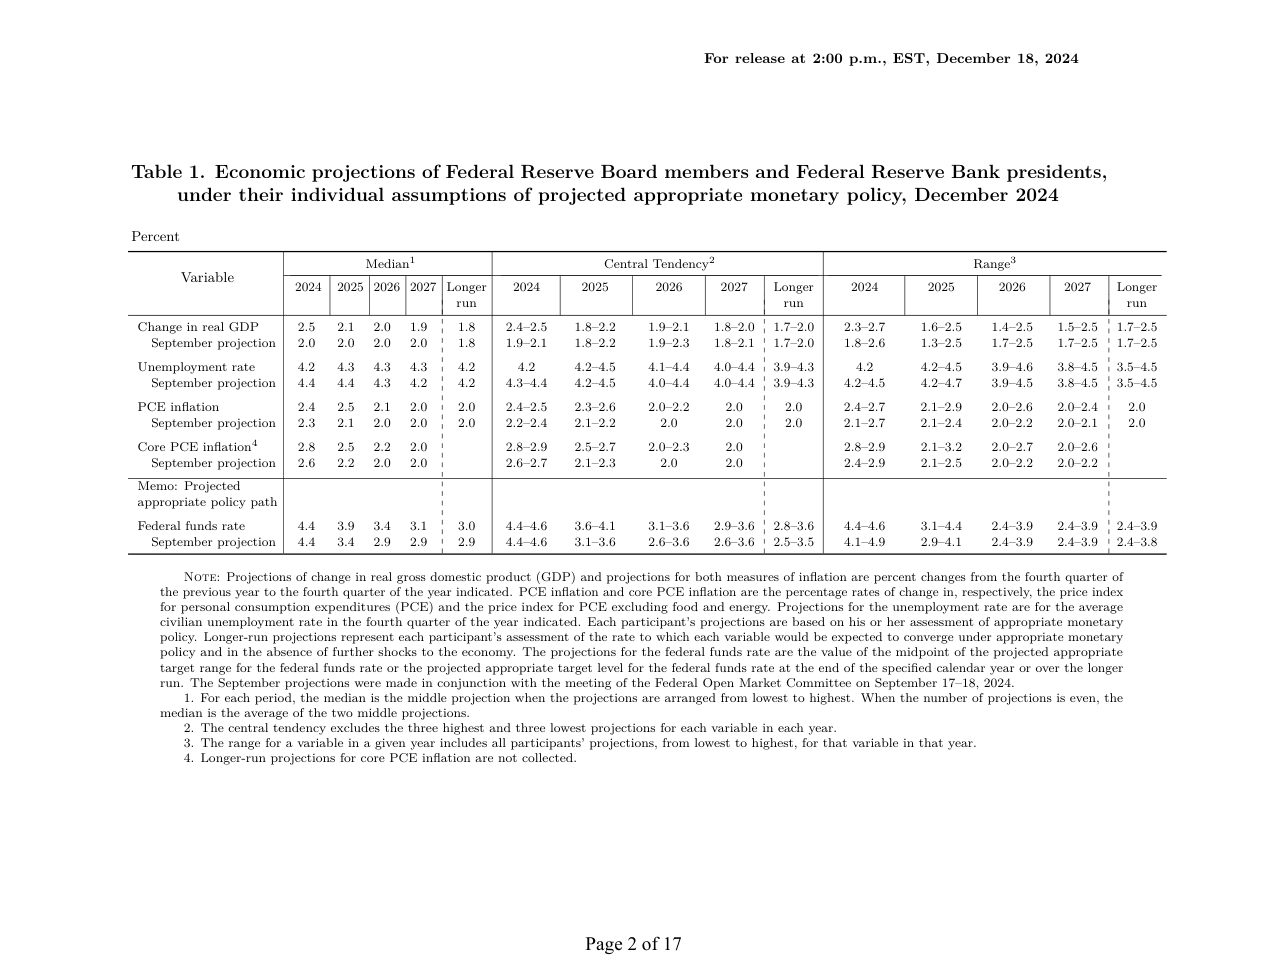


 Figure 2 — 금리 점도표 (PDF p.4)


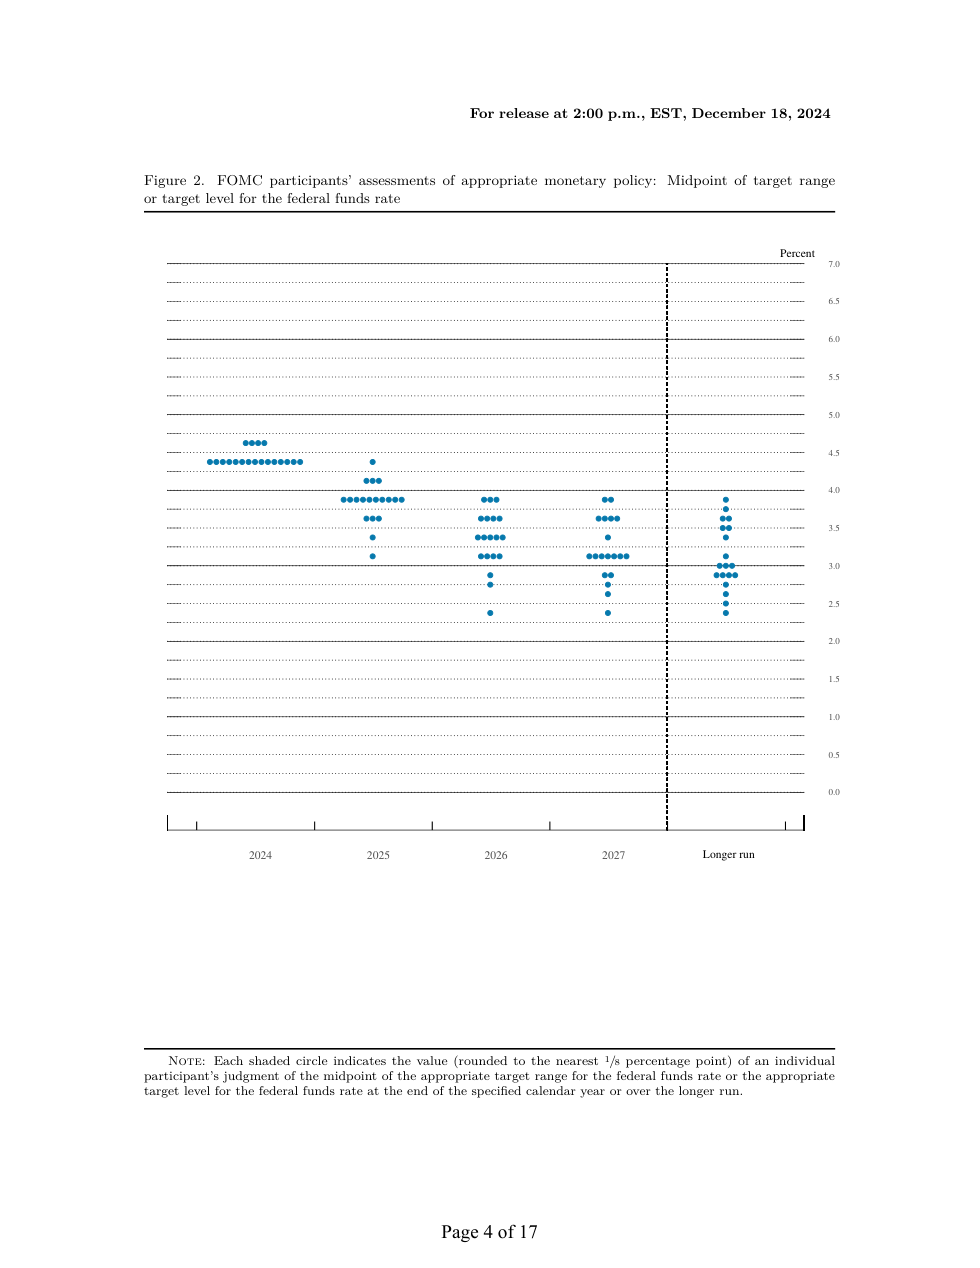


 Figure 4.A — GDP 불확실성 (PDF p.10)


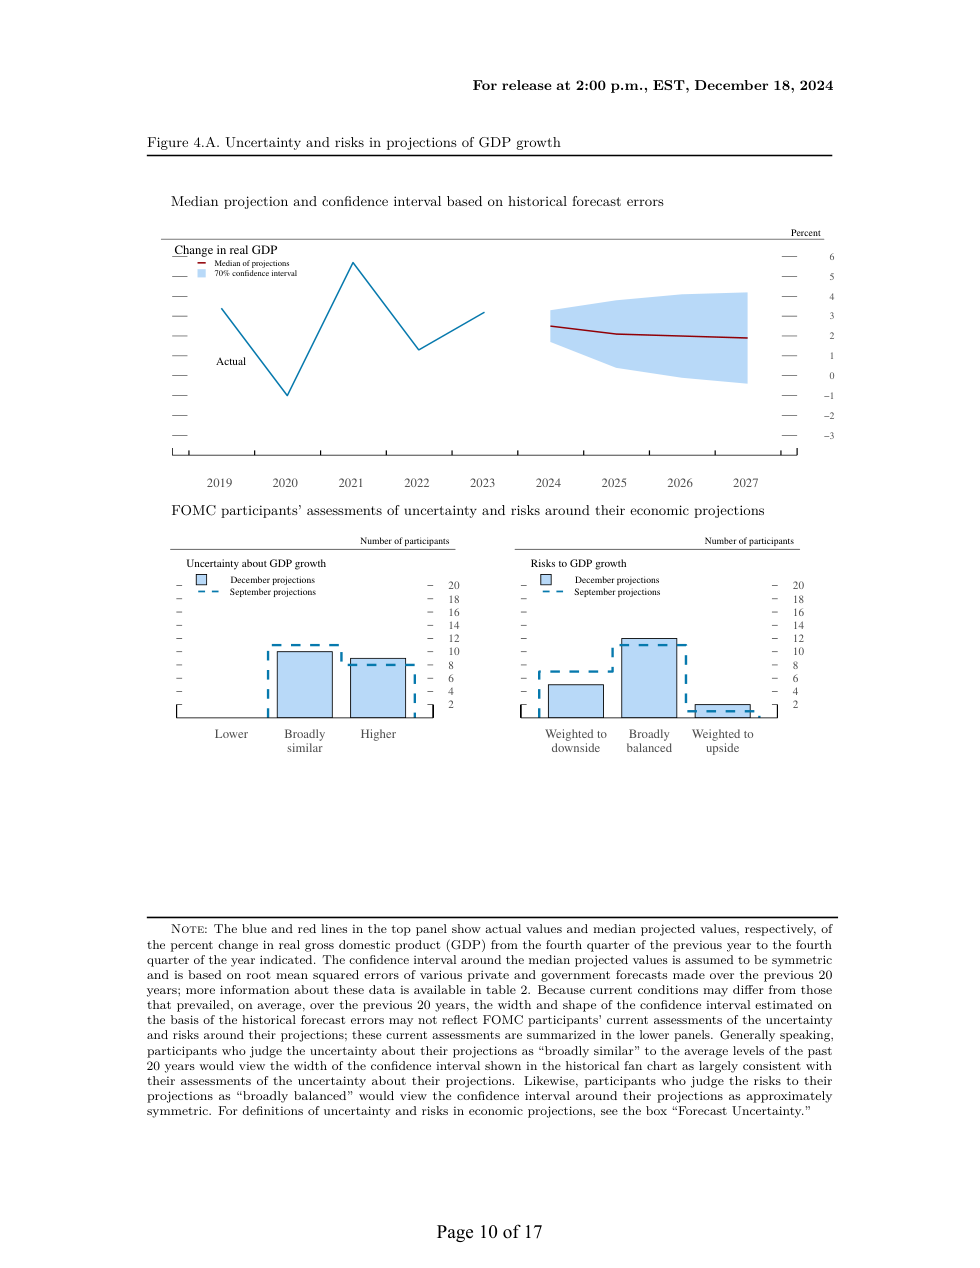

In [4]:
for name, label in [
    ("table1_economic_projections_p2.png", "Table 1 — 경제전망 표 (PDF p.2)"),
    ("figure2_dot_plot_p4.png", "Figure 2 — 금리 점도표 (PDF p.4)"),
    ("figure4a_gdp_uncertainty_p10.png", "Figure 4.A — GDP 불확실성 (PDF p.10)"),
]:
    img = FIGURES_DIR / name
    print("\n", label)
    if img.is_file():
        display(Image(filename=str(img), width=840))
    else:
        raise FileNotFoundError(f"이미지 없음: {img}")

## 2. 텍스트·표·이미지 요약 — 실습 02 (`summarize.py`)

사용 함수: `generate_text_summaries()`, `encode_image()`, `image_summarize()`, `generate_img_summaries()`.

이번 재실행 로그: **텍스트 요약 5개 / 표 요약 3개 / 이미지 요약 6개**. 원래 폴더의 JPG까지 읽던 방식을 바꿔 `extracted.pkl`에 기록된 PNG 6개만 처리했습니다.

**주의:** 일부 텍스트 요약은 다른 경제지표 수치가 섞였습니다. 요약 성공 개수는 정확성 판정이 아닙니다.

In [5]:
run_stage("summarize.py", PROCESSED_DIR / "summaries.pkl")

with (PROCESSED_DIR / "summaries.pkl").open("rb") as file:
    summarized = pickle.load(file)

text_summaries = summarized["text_summaries"]
table_summaries = summarized["table_summaries"]
image_summaries = summarized["image_summaries"]
image_raw_b64 = summarized["img_base64_list"]
image_names = summarized.get("image_file_names", [])

print("텍스트 원본 / 요약:", len(chunks), "/", len(text_summaries))
print("표 원본 / 요약:", len(tables), "/", len(table_summaries))
print("이미지 원본 / 요약:", len(image_raw_b64), "/", len(image_summaries))
assert len(chunks) == len(text_summaries)
assert len(tables) == len(table_summaries)
assert len(image_raw_b64) == len(image_summaries)

# 보안·파일 크기를 위해 Base64 전체 원문은 출력하지 않습니다.
for label, samples in [
    ("텍스트 요약", text_summaries),
    ("표 요약", table_summaries),
    ("이미지 요약", image_summaries),
]:
    if samples:
        print(f"\n[{label} 예시]\n{str(samples[0])[:650]}")

assert len(image_raw_b64) == 6, "이전 실습 이미지가 포함되지 않았는지 확인하세요."
assert set(image_names) == set(figure_names), "이번 PDF PNG 명단과 요약 이미지 명단이 다릅니다."
print("\n이미지 파일명 및 해당 요약 첫 부분:")
for name, summary in zip(image_names, image_summaries):
    print(f"- {name}: {str(summary)[:130]}...")

[저장 결과 사용] data\processed\summaries.pkl
텍스트 원본 / 요약: 5 / 5
표 원본 / 요약: 3 / 3
이미지 원본 / 요약: 6 / 6

[텍스트 요약 예시]
**경제전망 요약 (2024-2027)**

- **발표일**: 2024년 12월 18일 오후 2시 (EST)
- **참여자**: 연방공개시장위원회(FOMC) 회의 참가자들이 제출한 경제 전망
- **주요 변수**: 실질 국내총생산(GDP) 성장률, 실업률, 인플레이션

**2024-2027년 경제 전망**:
- **실질 GDP 성장률**: 
  - 2024: 1.7% - 2.5%
  - 2025: 1.7% - 2.5%
  - 2026: 3.5% - 4.5%
  - 2027: 3.5% - 4.5%
  - 장기 전망: 2.0%

- **실업률**:
  - 2024: 2.4% - 3.9%
  - 2025: 2.4% - 3.8%
  - 2026: 2.0%
  - 2027: 2.0%
  - 장기 전망: 2.0%

- **PCE 인플레이션**:
  - 2024: 2.4% - 3.9%
  - 2025: 2.4% - 3.8%
  - 2026: 2.0%
  - 2027: 2.0%
  - 장기 전망: 2.0%

- **핵심 PCE 인플레이션**: 장기 전망 수치 미제공

**참고사항**:
- 각 참가자의 전망은 적절한 통화 정책에 대한 평가를 기반으로 하며, 장기 전망은 경제 충격이 없을 경우 각 변수의 수렴 예상치를 나타냄.
- 중앙 경향은 각 변수의 가장 높

[표 요약 예시]
**경제전망 요약**

- **실질 GDP 변화율**: 
  - 2024: 2.5%, 2025: 2.1%, 2026: 2.0%, 2027: 1.9%, 장기: 1.8%
  - 중앙 경향: 2024: 2.4–2.5%, 2025: 1.8–2.2%, 2026: 1.9–2.1%, 2027: 1.8–2.0%
  - 범위: 2024: 2.3–2.7%, 2025: 1.6–2.5%, 2026: 1.4–2.5%

- **실업률

## 3. 검색·답변 생성 — 실습 03 (`retriever.py`)

**요약은 Chroma에 임베딩**, 원본은 **InMemoryStore에 `doc_id`로 연결**, `MultiVectorRetriever`가 관련 원본을 가져온 뒤 GPT-4o-mini가 답변합니다.

- 이번 재실행 결과: 벡터 저장 **14개** (텍스트 5 + 표 3 + 이미지 6)
- Figure 2 비교 질문: **검색 원본 8개** (이미지 4개 + 텍스트·표 4개)
- 질의응답: **5건 생성**

다음 셀은 저장된 응답 파일을 확인합니다. 이 노트북 자체가 임베딩과 API를 재호출하지는 않습니다.

In [6]:
run_stage("retriever.py", RESULTS_DIR / "qa_results.json")

required_results = [
    "qa_results.json", "qa_results.md",
    "before_after.txt", "before_after.png"
]
for name in required_results:
    target = RESULTS_DIR / name
    print(f"{'OK' if target.is_file() else '누락'}: results/{name}")

with (RESULTS_DIR / "qa_results.json").open("r", encoding="utf-8") as file:
    qa_records = json.load(file)

print("질의응답 개수:", len(qa_records))
assert len(qa_records) == 5, "질문 5건을 확인해 주세요."

print("\n[최신 실행 로그 확인 항목] 이미지 6개, 벡터 14개, 질의응답 5건")

[저장 결과 사용] results\qa_results.json
OK: results/qa_results.json
OK: results/qa_results.md
OK: results/before_after.txt
OK: results/before_after.png
질의응답 개수: 5

[최신 실행 로그 확인 항목] 이미지 6개, 벡터 14개, 질의응답 5건


### 실제 질의응답 5건 및 검색 원본 종류

다음 셀은 실제 `qa_results.json`에 저장된 질문, 모델 응답, 검색된 원본 종류를 **그대로** 출력합니다. 모델 답변은 원본 PDF와 별도로 대조해야 합니다.

In [7]:
for row in qa_records:
    question = row.get("question", "")
    answer = row.get("answer", "")
    sources = row.get("sources", [])
    source_names = []
    for item in sources:
        kind = item.get("type", "미분류")
        filename = item.get("file", "")
        source_names.append(f"{kind} ({filename})" if filename else kind)

    print("=" * 76)
    print(f"Q{row.get('number')}. {question}")
    print("[답변]", answer)
    print("[검색된 원본 종류]", ", ".join(dict.fromkeys(source_names)))
print("=" * 76)


Q1. Table 1에서 2025년 실질 GDP 성장률, 실업률, PCE 물가상승률 전망 중앙값은 각각 얼마인가요?
[답변] Table 1에서 2025년의 실질 GDP 성장률, 실업률, PCE 물가상승률 전망 중앙값은 다음과 같습니다:

- **실질 GDP 성장률 중앙값**: 2.1%
- **실업률 중앙값**: 4.3%
- **PCE 물가상승률 중앙값**: 2.5%

출처: 페이지 2.
[검색된 원본 종류] table, image (figure1_projection_ranges_p3.png), text, image (table2_historical_errors_p16.png), image (table1_economic_projections_p2.png)
Q2. Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교해 주세요.
[답변] Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교하면 다음과 같습니다.

### 2024년
- **점 분포**: 2024년의 점들은 대체로 4.0%에서 5.0% 사이에 집중되어 있으며, 일부는 5.0%를 초과하는 수준까지 분포하고 있습니다.
- **범위**: Table 1에 따르면, 2024년의 연방기금금리 범위는 4.4%에서 4.6% 사이입니다.

### 2025년
- **점 분포**: 2025년의 점들은 4.0%에서 5.5% 사이에 분포하고 있으며, 5.0%를 초과하는 점들도 존재합니다.
- **범위**: Table 1에 따르면, 2025년의 연방기금금리 범위는 4.4%에서 5.0% 사이입니다.

### 비교
- **2024년**은 4.0%에서 5.0% 사이에 점들이 집중되어 있는 반면, **2025년**은 더 넓은 범위인 4.0%에서 5.5%까지 분포하고 있습니다. 이는 2025년의 전망이 2024년에 비해 더 높은 금리 수준을 반영하고 있음을 나타냅니다.

이러한 점들은 각 연도에 대한 FOMC 참가자들의 적정 금리 수준에 대한 

## 4. Before / After — 같은 질문의 답변 비교

**질문:** “Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교해 주세요.”

| 구분 | BEFORE: 텍스트 RAG | AFTER: 멀티모달 RAG |
|---|---|---|
| 검색용 데이터 | 텍스트 요약 | 텍스트·표·이미지 요약 |
| 답변 원본 | 텍스트 원본 | 텍스트·표·이미지 원본 |
| 공통 요소 | `MultiVectorRetriever`, `gpt-4o-mini`, `k=8`, 프롬프트 | 동일 |

두 체인은 자료 유형이 다르므로 엄격하게 통제된 인과 실험은 아닙니다.**정확성 검증**은 다음 섹션을 참고하세요.

In [8]:
comparison_path = RESULTS_DIR / "before_after.txt"
comparison_image = RESULTS_DIR / "before_after.png"

if not comparison_path.is_file():
    raise FileNotFoundError(f"비교 결과 파일이 없습니다: {comparison_path}")

print(comparison_path.read_text(encoding="utf-8"))


질문: Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교해 주세요.

[BEFORE]
Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교하면 다음과 같습니다.

2024년의 경우, FOMC 참가자들이 제시한 적정 연방기금금리의 중간값은 약 4.0%로 보이며, 점들이 3.5%에서 4.5% 사이에 분포하고 있습니다. 반면, 2025년의 경우 중간값은 약 4.5%로 예상되며, 점들은 4.0%에서 5.0% 사이에 분포하고 있습니다.

이 두 연도의 점도표를 비교했을 때, 2024년의 금리 전망은 3.5%에서 4.5%로 상대적으로 좁은 범위에 집중되어 있는 반면, 2025년은 4.0%에서 5.0%로 다소 넓은 범위에 걸쳐 분포하고 있습니다. 이는 2025년의 금리 전망이 2024년에 비해 더 높은 수준으로 예상되고 있음을 나타냅니다. 

이와 같은 분포는 각 연도의 경제 상황과 정책 결정에 대한 참가자들의 기대가 반영된 결과로 해석될 수 있습니다.

[AFTER]
Figure 2의 점도표에서 2024년과 2025년 연말 적정 연방기금금리 전망 점들의 분포를 비교하면 다음과 같습니다.

### 2024년
- **점 분포**: 2024년의 점들은 대체로 4.0%에서 5.0% 사이에 집중되어 있으며, 일부는 5.0%를 초과하는 수준까지 분포하고 있습니다.
- **범위**: Table 1에 따르면, 2024년의 연방기금금리 범위는 4.4%에서 4.6% 사이입니다.

### 2025년
- **점 분포**: 2025년의 점들은 4.0%에서 5.5% 사이에 분포하고 있으며, 5.0%를 초과하는 점들도 존재합니다.
- **범위**: Table 1에 따르면, 2025년의 연방기금금리 범위는 4.4%에서 5.0% 사이입니다.

### 비교
- **2024년**은 4.0%에서 5.0% 사이에 점들이 집중되어 있는 반면, **2025년**은 더 넓은 범위인 4.0%에서 5.5%까지 분포하고 있

실제 실행 결과로 생성한 Before / After 비교 이미지


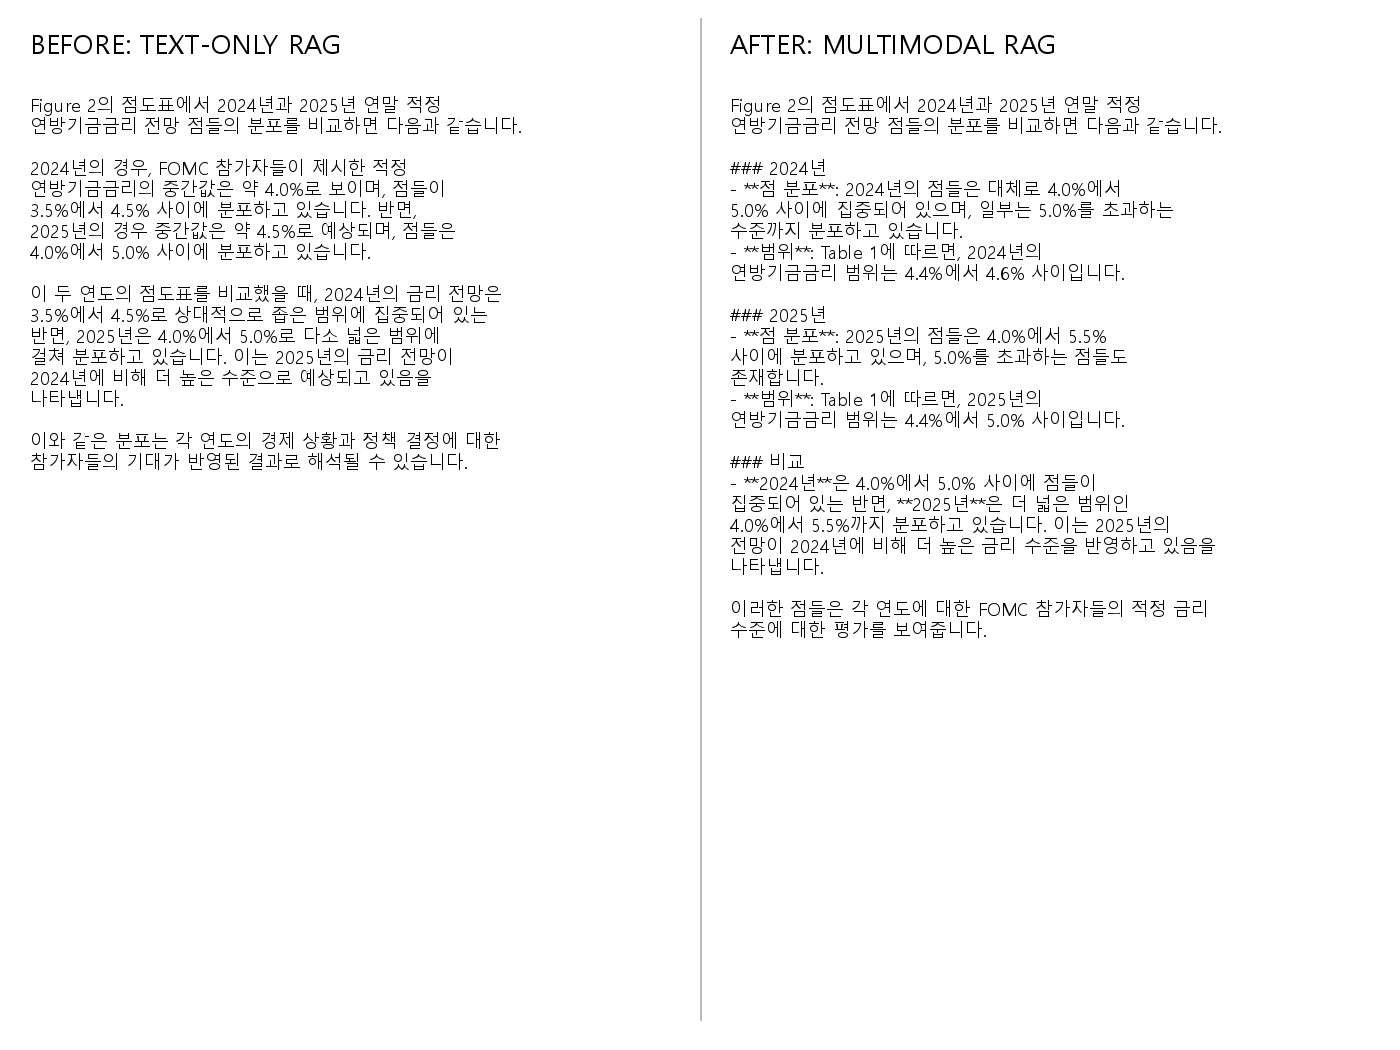

In [9]:
print("실제 실행 결과로 생성한 Before / After 비교 이미지")
if comparison_image.is_file():
    display(Image(filename=str(comparison_image), width=1060))
else:
    print("이미지 파일을 찾지 못했습니다:", comparison_image)


## 5. 원본 PDF 대조 · 검증 결과

**공식 원본**: [Federal Reserve, 2024.12.18 SEP (17p)](https://www.federalreserve.gov/monetarypolicy/files/fomcprojtabl20241218.pdf)

| 질문 | 검증 결과 | 주요 근거 |
|---|---|---|
| Q1 | ✅ 핵심 수치 일치 | 2025년 GDP **2.1%**, 실업률 **4.3%**, PCE **2.5%** (Table 1, p.2) |
| Q2 | ❌ 수치·방향 오류 | 2024년 금리 전망 중앙값 **4.4%**, Range **4.4–4.6%**; 2025년 중앙값 **3.9%**, Range **3.1–4.4%** (Table 1, p.2; Figure 2, p.4) |
| Q3 | ✅ 핵심 수치 일치 | GDP **2.5→2.1→2.0→1.9%**, 실업률 **4.2→4.3→4.3→4.3%** (p.2~3) |
| Q4 | ✅ 핵심 수치 일치 | 2027년 GDP **±2.3%p**, 실업률 **±2.0%p** (Table 2, p.16) |
| Q5 | ⚠️ 부분 확인 | 파란 선은 실제값, 빨간 선은 전망 중앙값, 연한 파란 영역은 70% 신뢰구간 (Figure 4.A, p.10). **참가자 수는 추가 검증 필요** |

**한계:** 이미지 검색 성공과 답변 정확성은 다른 문제이며, 텍스트 요약 자체에서 지표가 혼동될 수도 있습니다. 답변을 임의 수정하지 않고 원본 대조 결과를 별도로 기록합니다.

In [11]:
# 실제 파일을 기준으로 제출 준비 상태 검사
checks = {
    "텍스트/표 추출": len(texts) > 0 and len(tables) > 0,
    "이미지 파일 생성": len(figure_names) == 6 and all((FIGURES_DIR / name).is_file() for name in figure_names),
    "텍스트/표 요약": len(text_summaries) > 0 and len(table_summaries) > 0,
    "이미지 요약": len(image_summaries) == 6 and set(image_names) == set(figure_names),
    "질문 5건": len(qa_records) == 5,
    "비교 텍스트": comparison_path.is_file(),
    "비교 이미지": comparison_image.is_file(),
    "README 존재": (PROJECT_ROOT / "README.md").is_file(),
    ".gitignore 존재": (PROJECT_ROOT / ".gitignore").is_file(),
}
print("[실행 결과 파일 기준 점검]")
for name, ok in checks.items():
    print(("PASS" if ok else "CHECK"), "-", name)


[실행 결과 파일 기준 점검]
PASS - 텍스트/표 추출
PASS - 이미지 파일 생성
PASS - 텍스트/표 요약
PASS - 이미지 요약
PASS - 질문 5건
PASS - 비교 텍스트
PASS - 비교 이미지
PASS - README 존재
PASS - .gitignore 존재
